# All sites plot Land Exposure compared to Low Tide

For the selected date range, process Sentinel-2 scenes with less than 10% catalogue cloud cover at all configured sites. For each scene, record the nearest predicted low-tide time, height, and signed time offset; estimate whole-site dry area from SCL vegetation (class 4) and not-vegetated (class 5) pixels. Save per-site CSVs, RGB/SCL galleries, and dry-area-versus-low-tide scatter plots in each site's output folder.

In [1]:
import base64
import datetime
import html as html_module
import io
import os
import sys
import pathlib

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import plotly.express as px
import rasterio
import rasterio.features
import xarray
from IPython.display import FileLink, display

module_path = pathlib.Path.cwd().parent / 'scripts'
import sys
if str(module_path) not in sys.path:
    sys.path.append(str(module_path))
import utils
import sentinel2

## Date-Range Site and Cloud Settings

Set the start and end years and cloud-cover cutoff below. All matching scenes are retained; low-tide timing is recorded for comparison, not used to exclude scenes.

In [2]:
data_path = utils.get_data_path()

In [24]:
all_training_sites =  ["Ihutai", "CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua", "Purau",
              "IveyBay_Nov25", "IveyBay_Feb26", "LeftBank_Nov25", "LeftBank_Feb26", "Paremata_Nov25", "Paremata_Feb26",
              "Paremata_Feb25", "ThePoint_Nov25", "ThePoint_Feb26", "Takapuwahia_Nov25", "Takapuwahia_Feb26", "IveyBay_ThePoint_LeftBank_Oct24"]
sites = all_training_sites

years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

max_cloud_cover = 1

In [4]:
_, satellite_path = utils.get_prediction_path(
    sample_method="sampling_2", method_2_threshold=0.5,
    model_max_cloud_cover=max_cloud_cover,
    predict_max_cloud_cover=max_cloud_cover,
    satellite_only=True) 

mndwi_file = satellite_path / "mean_mndwi.csv"
output_path = satellite_path / "rbg_thumbnails_mndwi_sorted"
output_path.mkdir(exist_ok=True, parents=True)

### Templ cell while other ntoebook running to completion

In [25]:
sites = sites[0:3]
output_file = data_path / "mndwi_low_tide_thresholds.csv"
mndwi_thresholds = {"site": [], "threshold": []}
mean_mndwi_all_sites = []

for site in sites:
    mean_mndwi_series = []
    for year in years:
        print(f"{site}: year {year}")
    
        satellite_file = satellite_path / f"{site}_{year}_sentinel-2.nc"

        # load in satellite file
        satellite_data = utils.load_satellite(filename=satellite_file, chunks=None)
        # calculate MNDWI layer
        green = satellite_data["B03"].astype(numpy.float32)
        swir1 = satellite_data["B11"].astype(numpy.float32)
        scl = satellite_data["SCL"]

        valid_pixels = (
            scl.notnull()
            & (scl > 0)
            & ~scl.isin(sentinel2.SCL_TO_IGNORE)
            & (green > 0)
            & (swir1 > 0)
        )

        mndwi = ((green - swir1) / (green + swir1)).where(valid_pixels)
        mean_mndwi_series.append(
            mndwi.mean(dim=["x", "y"], skipna=True).compute().to_pandas()
        )
    mean_mndwi_series = pandas.concat(mean_mndwi_series)
    mndwi_thresholds["site"].append(site)  
    mndwi_thresholds["threshold"].append(mean_mndwi_series.quantile(0.20))
    mean_mndwi_all_sites.append(mean_mndwi_series)
mndwi_thresholds = pandas.DataFrame(mndwi_thresholds)
mndwi_thresholds.to_csv(output_file, index=False)

# for plotting the distributions
mean_mndwi_all_sites = pandas.concat(mean_mndwi_all_sites, keys=sites, names=["site", "time"]).rename("mean_mndwi")
mean_mndwi_all_sites.to_csv(satellite_file.with_name("mean_mndwi.csv"))


Ihutai: year 2016
Ihutai: year 2017
Ihutai: year 2018
Ihutai: year 2019
Ihutai: year 2020
Ihutai: year 2021
Ihutai: year 2022
Ihutai: year 2023
Ihutai: year 2024
Ihutai: year 2025
Ihutai: year 2026
CatlinsLake: year 2016
CatlinsLake: year 2017
CatlinsLake: year 2018
CatlinsLake: year 2019
CatlinsLake: year 2020
CatlinsLake: year 2021
CatlinsLake: year 2022
CatlinsLake: year 2023
CatlinsLake: year 2024
CatlinsLake: year 2025
CatlinsLake: year 2026
CatlinsRiverMouth: year 2016
CatlinsRiverMouth: year 2017
CatlinsRiverMouth: year 2018
CatlinsRiverMouth: year 2019
CatlinsRiverMouth: year 2020
CatlinsRiverMouth: year 2021
CatlinsRiverMouth: year 2022
CatlinsRiverMouth: year 2023
CatlinsRiverMouth: year 2024
CatlinsRiverMouth: year 2025
CatlinsRiverMouth: year 2026


In [5]:
scl_classes = [
    (0, "No data", "#000000"),
    (1, "Saturated/defective", "#ff0000"),
    (2, "Dark area", "#2f2f2f"),
    (3, "Cloud shadow", "#643200"),
    (4, "Vegetation", "#00a000"),
    (5, "Not vegetated", "#ffe65a"),
    (6, "Water", "#0000ff"),
    (7, "Unclassified", "#808080"),
    (8, "Cloud, medium probability", "#c0c0c0"),
    (9, "Cloud, high probability", "#ffffff"),
    (10, "Thin cirrus", "#64c8ff"),
    (11, "Snow/ice", "#ff96ff"),
]
scl_legend_html = '<div class="legend">' + "".join(
    f'<span class="legend-item"><i style="background:{color}"></i>{code}: '
    f'{html_module.escape(label)}</span>'
    for code, label, color in scl_classes
) + "</div>"


def make_gallery(site_name, gallery_title, cards, output_file, legend_html=""):
    gallery_style = """
:root { color-scheme: light; font-family: "Segoe UI", sans-serif; color: #202a33; background: #f3f5f6; }
body { margin: 0; padding: 20px; }
header, .gallery, .legend { max-width: 1500px; margin: 0 auto 16px; }
h1 { margin: 0 0 6px; font-size: 22px; }
p { margin: 0; color: #56616b; }
.gallery { display: grid; grid-template-columns: repeat(auto-fill, minmax(min(320px, 100%), 1fr)); gap: 14px; }
.scene { min-width: 0; overflow: hidden; background: white; border: 1px solid #d5dce1; border-radius: 5px; }
.scene h2 { margin: 10px 12px 0; font-size: 15px; }
.scene img { display: block; width: 100%; aspect-ratio: 4 / 3; object-fit: contain; background: #f7f8f8; }
.caption { padding: 8px 12px 11px; font-size: 12px; line-height: 1.4; }
.legend { display: flex; flex-wrap: wrap; gap: 6px 12px; padding: 10px; background: white; border: 1px solid #d5dce1; }
.legend-item { display: inline-flex; align-items: center; gap: 5px; font-size: 11px; }
.legend-item i { display: inline-block; width: 14px; height: 14px; border: 1px solid #7b858c; }
@media (max-width: 600px) { body { padding: 10px; } }
"""
    page = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{html_module.escape(site_name)} {DATE_RANGE_LABEL} {html_module.escape(gallery_title)}</title>
<style>{gallery_style}</style>
</head>
<body>
<header><h1>{html_module.escape(site_name)}: {DATE_RANGE_LABEL} {html_module.escape(gallery_title)}</h1>
<p>{len(cards)} scenes with catalogue cloud cover under {MAX_CLOUD_COVER_PCT:g}%.</p></header>
{legend_html}
<main class="gallery">{''.join(cards)}</main>
</body>
</html>"""
    output_file.write_text(page, encoding="utf-8")
    print(f"  Saved {output_file}")

In [6]:
def time_key(timestamp):
    return timestamp.strftime("%Y-%m-%d %H:%M:%S.%f")


def load_site_scenes(site_name, mndwi):
    site_rows = mndwi.loc[mndwi["site"] == site_name].copy()
    site_rows["time"] = pandas.to_datetime(site_rows["time"])
    mndwi_by_time = {
        time_key(timestamp): value
        for timestamp, value in zip(site_rows["time"], site_rows["mean_mndwi"])
    }

    scenes = []
    for year in years:
        satellite_file = satellite_path / f"{site_name}_{year}_sentinel-2.nc"
        if not satellite_file.exists():
            continue

        satellite_data = utils.load_satellite(filename=satellite_file, chunks=None)

        for scene_index, scene_time in enumerate(satellite_data.time.values):
            rgb = numpy.stack(
                [
                    satellite_data[band].isel(time=scene_index).values
                    for band in sentinel2.RGB_BANDS
                ],
                axis=-1,
            ).astype(numpy.float32)

            scenes.append(
                (mndwi_by_time.get(time_key(scene_time), numpy.nan), scene_time, rgb)
            )

    scenes.sort(
        key=lambda scene: (
            pandas.isna(scene[0]),
            -scene[0] if pandas.notna(scene[0]) else 0,
        )
    )
    return scenes


def make_rgb_cards(site_name, scenes):
    cards = []
    for mndwi_value, scene_time, rgb in scenes:
        valid = numpy.isfinite(rgb).all(axis=-1) & (rgb > 0).all(axis=-1)
        display_rgb = numpy.ones_like(rgb)

        if valid.any():
            for channel in range(3):
                pixels = rgb[..., channel][valid]
                low, high = numpy.percentile(pixels, [2, 98])
                if high > low:
                    display_rgb[..., channel] = numpy.clip(
                        (rgb[..., channel] - low) / (high - low), 0, 1
                    )

        display_rgb[~valid] = 1
        image_buffer = io.BytesIO()
        figure, axis = plt.subplots(figsize=(5, 3.75))
        axis.imshow(display_rgb)
        axis.axis("off")
        figure.savefig(
            image_buffer,
            format="jpg",
            dpi=90,
            bbox_inches="tight",
            pad_inches=0,
            pil_kwargs={"quality": 84, "optimize": True},
        )
        plt.close(figure)

        image = base64.b64encode(image_buffer.getvalue()).decode("ascii")
        date_label = html_module.escape(scene_time.strftime("%Y-%m-%d %H:%M"))
        value_label = f"{mndwi_value:.3f}" if pandas.notna(mndwi_value) else "unavailable"
        cards.append(
            f'<article class="scene"><h2>{date_label}</h2>'
            f'<img src="data:image/jpeg;base64,{image}" alt="{site_name} RGB {date_label}">'
            f'<div class="caption">Mean MNDWI: {value_label}</div></article>'
        )

    return cards

In [27]:
mndwi = pandas.read_csv(mndwi_file)

for site in sites:
    print(f"\tSite {site}")
    scenes = load_site_scenes(site, mndwi)
    cards = make_rgb_cards(site, scenes)
    
    DATE_RANGE_LABEL = f"{min(years)}-{max(years)}"
    MAX_CLOUD_COVER_PCT = max_cloud_cover
    gallery_file = output_path / f"{site}_rgb_by_mean_mndwi.html"
    
    make_gallery(site, "RGB scenes by mean MNDWI", cards, gallery_file)

	Site {site}
  Saved C:\Local\repos\seagrass-detection\data\predictions\cloud_1\satellite_images\rbg_thumbnails_mndwi_sorted\Ihutai_rgb_by_mean_mndwi.html
	Site {site}
  Saved C:\Local\repos\seagrass-detection\data\predictions\cloud_1\satellite_images\rbg_thumbnails_mndwi_sorted\CatlinsLake_rgb_by_mean_mndwi.html
	Site {site}
  Saved C:\Local\repos\seagrass-detection\data\predictions\cloud_1\satellite_images\rbg_thumbnails_mndwi_sorted\CatlinsRiverMouth_rgb_by_mean_mndwi.html


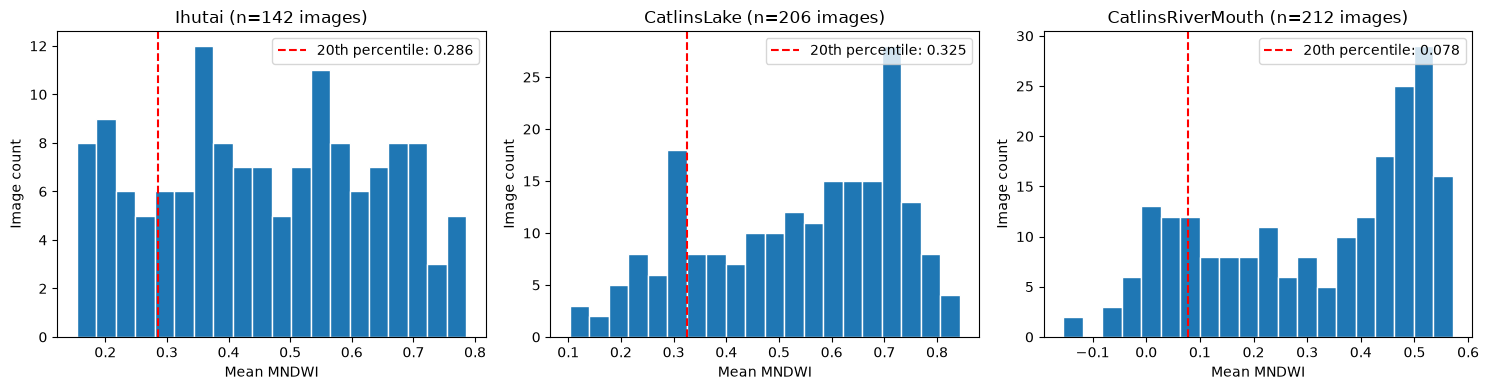

In [28]:
mean_mndwi_all_sites = pandas.read_csv(satellite_path /"mean_mndwi.csv")

ncols = 3
nrows = int(numpy.ceil(len(sites) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False
)

for axis, site in zip(axes.flat, sites):
    values = mean_mndwi_all_sites[mean_mndwi_all_sites["site"]==site].dropna()["mean_mndwi"]

    # Plot values in this site's histogram
    axis.hist(values, bins=20, edgecolor="white")
    axis.set_title(f"{site} (n={len(values)} images)")
    axis.set_xlabel("Mean MNDWI")
    axis.set_ylabel("Image count")

    if not values.empty:
        percentile_20 = numpy.percentile(values, 20)
        axis.axvline(
            percentile_20,
            color="red",
            linestyle="--",
            label=f"20th percentile: {percentile_20:.3f}",
        )
        axis.legend()

for axis in axes.flat[len(sites):]:
    axis.set_visible(False)

fig.tight_layout()
plt.show()